# Zero-shot DC solution proposal workflow

This notebook documents the workflow used to prepare model-generated DC solution proposals for expert assessment.

## Workflow

1. Retain model-variant groups containing the complete 50 iterations.
2. Clean formatting inconsistencies in the generated responses, including Markdown markers, numbering, generic labels, and misplaced titles or explanations. Retain a maximum of five proposals per model variant and iteration.
3. Combine each proposal title and explanation and calculate its maximum semantic similarity to the 11 DC solutions provided in the prompt using BAAI/bge-large-en-v1.5. Retain proposals with a similarity score below 0.60.
4. Embed the retained proposals using BAAI/bge-large-en-v1.5 and cluster them using HDBSCAN.
5. Generate cluster labels and t-SNE visualisations to support inspection of the resulting clusters.
6. Review the eight non-noise clusters, consolidate related themes, and record five author-generated proposals for expert assessment.
7. Evaluate the semantic fidelity of the five authored proposals against their source-cluster evidence.

In [ ]:
import pandas as pd

df = pd.read_csv("solutionPropose_zeroshot.csv")

# --- 1) Count unique iterations per (base_model, variant_id)
counts = (
    df.groupby(['base_model', 'variant_id'])['iteration']
      .nunique()
      .rename('n_iters')
      .reset_index()
)
# keep only complete 50-iteration groups
valid_counts = counts[counts['n_iters'] == 50][['base_model', 'variant_id']]

# --- 2) Filter original dataframe based on valid_counts
merged_df = df.merge(valid_counts, on=['base_model', 'variant_id'], how='inner')

merged_df.to_csv("1_solutionPropose_zeroshot_valid_iter.csv", index=False)

print(f"before filtration: {len(df)}")
print(f"after filtration: {len(merged_df)}")

before filtration: 5738
after filtration: 5738


In [ ]:
# CLEANING STEP 1: Recover title from explanation prefix "Title: ..."

import re
import os
import pandas as pd

# Edit paths/columns as needed
input_path = "1_solutionPropose_zeroshot_valid_iter.csv"
out_dir = "cleaning_steps_zeroshot"
output_path = os.path.join(out_dir, "01_title_from_expl_zeroshot.csv")

title_col = "solution_title"
expl_col  = "explanation"

# --- Setup
os.makedirs(out_dir, exist_ok=True)
df = pd.read_csv(input_path)

# Safety: ensure columns exist
missing = [c for c in (title_col, expl_col) if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

# Regex: start-of-string <title> : <body>
pat = re.compile(r"^\s*(?P<title>[^:\n]{3,100}?)\s*:\s*(?P<body>.+)$")

# Work with strings
ex_str = df[expl_col].astype(str)

# Count before
before = int(ex_str.str.match(pat).sum())

def fix_row(row):
    text = str(row[expl_col])
    m = pat.match(text)
    if not m:
        return row
    extracted_title = m.group("title").strip()
    body = m.group("body").strip()
    # Replace title only if it's empty or generic "Solution N"
    current_title = str(row[title_col])
    if (not current_title.strip()) or re.fullmatch(r"(?i)\s*solution\s*\d+\s*", current_title or ""):
        row[title_col] = extracted_title
    row[expl_col] = body
    return row

df = df.apply(fix_row, axis=1)

# Count after
after = int(df[expl_col].astype(str).str.match(pat).sum())
print(f"Recovered from prefix: {before} rows -> {after} rows remaining with prefix")

# view remaining rows with prefix
remaining = df[df[expl_col].astype(str).str.match(pat)]
print(remaining[[title_col, expl_col]])

# Save
df.to_csv(output_path, index=False)
print(f"Saved cleaned file to: {output_path}")

Recovered from prefix: 1113 rows -> 0 rows remaining with prefix
Empty DataFrame
Columns: [solution_title, explanation]
Index: []
Saved cleaned file to: cleaning_steps_zeroshot/01_title_from_expl_zeroshot.csv


In [ ]:
# second step: Normalize label rows -> map labels into Title/Explanation
# by merging consecutive rows labeled as "Short Title" and "Brief Explanation"

import os
import pandas as pd

# --- Config
input_path  = "cleaning_steps_zeroshot/01_title_from_expl_zeroshot.csv"
out_dir     = "cleaning_steps_zeroshot"
output_path = os.path.join(out_dir, "02_labels_normalized_zeroshot.csv")

# STEP 2 (reworked): Merge consecutive "Short Title" + "Brief Explanation" rows into one;
# if only "Short Title" exists, move its text from explanation -> solution_title.

# Column names
label_col   = "solution_title"            # column that contains 'Short Title' / 'Brief Explanation'
content_col = "explanation"      # column that currently holds the text for those label-rows
title_col   = "solution_title"   # target title column
expl_col    = "explanation"      # target explanation column (same as content_col by default)

# Columns that identify the SAME response/run (must be identical to be merged)
group_cols  = ["base_model", "variant_id", "iteration"]

# Accepted labels (case-insensitive)
TITLE_LABELS = {"short title", "solution title", "title"}
EXPL_LABELS  = {"brief explanation", "explanation", "short explanation"}

os.makedirs(out_dir, exist_ok=True)
df = pd.read_csv(input_path)

# Safety checks
missing = [c for c in [label_col, content_col, title_col, expl_col] + group_cols if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Normalize a helper label column (without altering original)
lab_norm = df[label_col].astype(str).str.strip().str.lower()

# We will iterate in order and build a new list of rows
rows = []
i = 0
merged_pairs = 0
promoted_titles = 0

while i < len(df):
    row = df.iloc[i].copy()
    lab = lab_norm.iloc[i]

    # Helper to compare "same response" keys with the next row
    def same_group(idx1, idx2):
        if idx2 >= len(df):
            return False
        return all(df.iloc[idx1][c] == df.iloc[idx2][c] for c in group_cols)

    # Case A: current row is a Short Title
    if lab in TITLE_LABELS:
        # Look ahead 
        if i + 1 < len(df) and same_group(i, i + 1):
            next_lab = lab_norm.iloc[i + 1]
            if next_lab in EXPL_LABELS:
                # Merge pair
                row[title_col] = str(row[content_col]).strip()
                row[expl_col]  = str(df.iloc[i + 1][content_col]).strip()
                rows.append(row)
                i += 2
                merged_pairs += 1
                continue
        # Case A2: only Short Title exists (no matching Brief Explanation next)
        row[title_col] = str(row[content_col]).strip()
        # If explanation was just the short title text
        if str(row[expl_col]).strip() == str(row[content_col]).strip():
            row[expl_col] = ""
        rows.append(row)
        i += 1
        promoted_titles += 1
        continue

    # Case B: current row is a Brief Explanation without an immediate preceding Short Title
    if lab in EXPL_LABELS:
        if not str(row[expl_col]).strip():
            row[expl_col] = str(row[content_col]).strip()
        rows.append(row)
        i += 1
        continue

    # Case C: any other row (not labeled as title/explanation) — pass through
    rows.append(row)
    i += 1

# Build new DataFrame
df_merged = pd.DataFrame(rows, columns=df.columns)

print(f"Merged consecutive Short Title + Brief Explanation pairs: {merged_pairs}")
print(f"Promoted lone Short Title to solution_title: {promoted_titles}")

df_merged.to_csv(output_path, index=False)
print(f"Saved: {output_path}")

Merged consecutive Short Title + Brief Explanation pairs: 114
Promoted lone Short Title to solution_title: 17
Saved: cleaning_steps_zeroshot/02_labels_normalized_zeroshot.csv


In [ ]:
# check if remained with 'short title' or 'brief explanation' in 'solution_title' column
import pandas as pd
import os, re

# --- Config
input_path  = "cleaning_steps_zeroshot/02_labels_normalized_zeroshot.csv"
out_dir     = "cleaning_steps_zeroshot"
output_path = os.path.join(out_dir, "03_drop_generic_titles_zeroshot.csv")
corrected_csv = os.path.join(out_dir, "03_corrected_rows_zeroshot.csv")

title_col = "solution_title"
expl_col  = "explanation"

os.makedirs(out_dir, exist_ok=True)
df = pd.read_csv(input_path)

# 1) Identify "Solution N" placeholder titles
pat_generic = re.compile(r"(?i)^\s*solution\s*\d+\s*$")
mask_generic = df[title_col].astype(str).str.match(pat_generic)
n_generic = int(mask_generic.sum())
print(f"Rows with generic 'Solution N' title: {n_generic}")

if n_generic == 0:
    # Nothing to fix
    df.to_csv(output_path, index=False)
    print(f"No generic titles found. Saved unchanged → {output_path}")
else:
    work = df.copy()
    target = work[mask_generic].copy()

    # 2) Clean special characters
    def drop_specials(s: str) -> str:
        s = s or ""
        s = re.sub(r"[\*\^\$]+", "", s)       # remove ** ^ $
        s = re.sub(r"[ \t]+", " ", s)         # collapse spaces/tabs
        return s.strip()

    has_expl = target[expl_col].astype(str).str.strip() != ""
    target.loc[has_expl, expl_col] = target.loc[has_expl, expl_col].astype(str).map(drop_specials)
    n_cleaned = int(has_expl.sum())

    # 3) Try to split "<title>: <explanation>" (first colon only)
    split_pat = re.compile(r"^\s*(?P<title>[^:\n]{3,150}?)\s*:\s*(?P<body>.+)$")

    n_split = 0
    n_fallback_copy = 0

    for idx in target.index:
        expl_text = str(target.at[idx, expl_col]).strip()
        if not expl_text:
            # Nothing to use; leave as-is
            continue

        m = split_pat.match(expl_text)
        if m:
            # Split into proper title/explanation
            target.at[idx, title_col] = m.group("title").strip()
            target.at[idx, expl_col]  = m.group("body").strip()
            n_split += 1
        else:
            # Fallback: copy full explanation into title
            target.at[idx, title_col] = expl_text
            # leave explanation as-is
            n_fallback_copy += 1

    # 4) Merge corrected rows back
    work.loc[target.index, [title_col, expl_col]] = target[[title_col, expl_col]]

    # Save outputs
    work.to_csv(output_path, index=False)
    target.to_csv(corrected_csv, index=False)

    print(f"Explanation cleaned (special chars stripped) for: {n_cleaned} rows")
    print(f"Rows split '<title>: <explanation>': {n_split}")
    print(f"Rows fallback-copied explanation → title: {n_fallback_copy}")
    print(f"Saved full cleaned → {output_path}")
    print(f"Saved corrected rows → {corrected_csv}")

Rows with generic 'Solution N' title: 124
Explanation cleaned (special chars stripped) for: 124 rows
Rows split '<title>: <explanation>': 0
Rows fallback-copied explanation → title: 124
Saved full cleaned → cleaning_steps_zeroshot/03_drop_generic_titles_zeroshot.csv
Saved corrected rows → cleaning_steps_zeroshot/03_corrected_rows_zeroshot.csv


In [ ]:
# STEP 4: Strip markdown (** **) in title and split leaked explanation from title

import os, re
import pandas as pd

# --- Config
input_path  = "cleaning_steps_zeroshot/03_drop_generic_titles_zeroshot.csv" # clean csv
out_dir     = "cleaning_steps_zeroshot"
output_path = os.path.join(out_dir, "04_markdown_stripped_and_split_zeroshot.csv")
log_path    = os.path.join(out_dir, "04_title_split_log_zeroshot.csv")

title_col = "solution_title"
expl_col  = "explanation"

os.makedirs(out_dir, exist_ok=True)
df = pd.read_csv(input_path)

# Precompile once for speed/clarity
_LEADING_MARKERS_RE = re.compile(
    r"""
    ^\s*
    (?:
        =-                  |   # "=- "
        -{1,3}              |   # "-" or "--" or "---"
        [–—-]               |   # en/em dash or hyphen
        \*                  |   # "*"
        \+                  |   # "+"
        \#{1,6}             |   # "#", "##", ... "######"
        [•·]                |   # bullet chars
        \d+\.\s+            |   # "1. "
        \d+\)\s+            |   # "10) "
        [A-Za-z]\)\s+       |   # "b) "
        (?:[ivxlcdm]+)\)\s+ |   # "ii) " (roman numerals)
        \([A-Za-z0-9]\)\s+  |   # "(a) "
        \[[A-Za-z0-9]\]\s+      # "[A] "
    )
    \s*
    """,
    re.VERBOSE | re.IGNORECASE,
)

_MARKDOWN_WRAPPERS_RE = re.compile(r"(\*\*|__|`)+")
_SPACES_RE = re.compile(r"[ \t]+")

def strip_md_title(s: str) -> str:
    if s is None:
        return ""
    s = str(s)

    # 1) remove simple markdown wrappers
    s = _MARKDOWN_WRAPPERS_RE.sub("", s)

    # 2) strip leading list/heading markers
    s = _LEADING_MARKERS_RE.sub("", s)

    # 3) normalize spaces
    s = _SPACES_RE.sub(" ", s).strip()
    return s

# strip light markdown from explanation fragments too (rare but safe)
def strip_md_expl(s: str) -> str:
    s = s or ""
    # remove only obvious noise: paired **, __, stray backticks
    s = re.sub(r"(\*\*|__|`)+", "", s)
    # keep punctuation, collapse spaces
    s = re.sub(r"[ \t]+", " ", s)
    return s.strip()

# If explanation starts with "Title: " (case-insensitive), drop that prefix once
def strip_leftover_title_prefix(title: str, expl: str) -> str:
    if not title or not expl:
        return expl or ""
    pat = re.compile(rf"^\s*{re.escape(title)}\s*:\s*", flags=re.IGNORECASE)
    return pat.sub("", expl, count=1)

# Patterns to detect "**Title** Explanation" or "**Title**: Explanation"
PAT_BOLD_TRAIL = re.compile(
    r"""^\s*
        (?:
            \*{2}(?P<head_bold>.+?)\*{2}     # **Title**
            |
            __ (?P<head_und>.+?) __          # __Title__
        )
        \s*                                   # optional space
        (?:
            [:;\-–—]\s*                       # optional punctuation delimiter
        )?
        (?P<trail>.+)$                        # trailing prose
    """,
    re.VERBOSE | re.DOTALL,
)

# As a *fallback*
PAT_EARLY_COLON = re.compile(r"^\s*(?P<head>[^:\n]{3,120})\s*:\s*(?P<trail>.+)$")


# --- Process
rows_changed = []
split_count = 0
strip_count = 0
fallback_colon_splits = 0

# First, strip markdown from *all* titles (even when not splitting)
df[title_col] = df[title_col].astype(str)
stripped_titles = df[title_col].map(strip_md_title)
strip_count = int((stripped_titles != df[title_col]).sum())
df[title_col] = stripped_titles

# Title contains both a bolded head and trailing prose
for idx, row in df.iterrows():
    t_raw = row[title_col] if pd.notna(row[title_col]) else ""
    e_raw = row[expl_col]  if pd.notna(row[expl_col])  else ""
    t = str(t_raw).strip()
    e = str(e_raw).strip()

    # Only attempt split if explanation is empty
    may_fill_expl = (e == "") or (e.lower().startswith(t.lower() + ":") if t else False)

    if t:
        m = PAT_BOLD_TRAIL.match(t_raw)  # use raw to catch original markers
        if m and may_fill_expl:
            head = m.group("head_bold") or m.group("head_und") or ""
            trail = m.group("trail") or ""
            head_clean = strip_md_title(head)
            trail_clean = strip_md_expl(trail)

            # apply
            new_title = head_clean or t
            new_expl  = strip_leftover_title_prefix(new_title, trail_clean)

            if new_title != t or (may_fill_expl and new_expl):
                df.at[idx, title_col] = new_title
                if may_fill_expl:
                    df.at[idx, expl_col]  = new_expl
                rows_changed.append(idx)
                split_count += 1
                continue

        # Fallback: early-colon split in title only if explanation is empty/dup-prefix
        # Example: "DC Chargers: This solution ..." (no markdown)
        m2 = PAT_EARLY_COLON.match(t)
        if m2 and may_fill_expl:
            head_clean = strip_md_title(m2.group("head"))
            trail_clean = strip_md_expl(m2.group("trail"))
            new_title = head_clean or t
            new_expl  = strip_leftover_title_prefix(new_title, trail_clean)

            df.at[idx, title_col] = new_title
            if may_fill_expl:
                df.at[idx, expl_col] = new_expl
            rows_changed.append(idx)
            fallback_colon_splits += 1

# Optional: light cleanup on explanation (markdown noise)
df[expl_col] = df[expl_col].astype(str).map(strip_md_expl)

# Save artifacts
df.to_csv(output_path, index=False)
print(f"Saved: {output_path}")
print(f"Titles with markdown stripped: {strip_count}")
print(f"Rows split via bold/markdown pattern: {split_count}")
print(f"Rows split via early-colon fallback: {fallback_colon_splits}")

# Save a small log of changed rows for verification
if rows_changed:
    log_df = df.loc[sorted(set(rows_changed))].copy()
    log_df.to_csv(log_path, index=False)
    print(f"Logged {len(set(rows_changed))} changed rows → {log_path}")
else:
    print("No rows required splitting; only markdown stripping may have occurred.")

Saved: cleaning_steps_zeroshot/04_markdown_stripped_and_split_zeroshot.csv
Titles with markdown stripped: 1519
Rows split via bold/markdown pattern: 0
Rows split via early-colon fallback: 0
No rows required splitting; only markdown stripping may have occurred.


In [ ]:
import pandas as pd
import re
df = pd.read_csv("cleaning_steps_zeroshot/04_markdown_stripped_and_split_zeroshot.csv")

# count rows which at solution_title still have 'explanation' case-insensitive
mask = df['solution_title'].str.contains('explanation', case=False, na=False)

# drop those rows
df_cleaned = df[~mask].copy()
df_cleaned.to_csv("cleaning_steps_zeroshot/05_cleaned_after_explanation_drop_zeroshot.csv", index=False)
df_cleaned.info()
print(f"Dropped {mask.sum()} rows with 'explanation' in solution_title")

<class 'pandas.core.frame.DataFrame'>
Index: 5509 entries, 0 to 5623
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   row_id          5509 non-null   object
 1   base_model      5509 non-null   object
 2   variant_id      5509 non-null   object
 3   model           5509 non-null   object
 4   solution_title  5509 non-null   object
 5   explanation     5327 non-null   object
 6   iteration       5509 non-null   int64 
 7   timestamp       5509 non-null   object
 8   truncated       5509 non-null   object
 9   condition       5509 non-null   object
 10  is_duplicate    5509 non-null   object
dtypes: int64(1), object(10)
memory usage: 516.5+ KB
Dropped 115 rows with 'explanation' in solution_title


In [ ]:
# trimming part of explanation if it matches "<title> : <body>" but there is title already present
import pandas as pd
import re

df = pd.read_csv("cleaning_steps_zeroshot/05_cleaned_after_explanation_drop_zeroshot.csv")

# pattern to match "<title> : <body>"
pattern = r"^\s*(?P<title>[^:\n]{3,150}?)\s*:\s*(?P<body>.+)$"

# Create mask for non-null explanations
mask = df['explanation'].notna()

# Apply pattern matching to the masked rows
matching_bool = df.loc[mask, 'explanation'].str.match(pattern)
matching_rows = pd.Series(False, index=df.index)  # Initialize all False
matching_rows[mask] = matching_bool  # Set True only for matching rows

# Show counts and examples
print(f"\nTotal rows with non-null explanations: {mask.sum()}")
print(f"Of these, rows matching title:body pattern: {matching_bool.sum()}")

# Show examples of both matching and non-matching
if matching_bool.any():
    print("\nExample MATCHING rows:")
    print(df.loc[matching_rows, 'explanation'].head().to_string())
    
print("\nExample NON-MATCHING rows:")
print(df.loc[mask & ~matching_rows, 'explanation'].head().to_string())

# all rows under 'matching_rows' trim the part of the context from 'explanation...'
df.loc[matching_rows, 'explanation'] = df.loc[matching_rows, 'explanation'].str.replace(pattern, r"\2", regex=True)
df.to_csv("cleaning_steps_zeroshot/06_final_cleaned_data_zeroshot.csv", index=False)



Total rows with non-null explanations: 5327
Of these, rows matching title:body pattern: 1

Example MATCHING rows:
5183    A lighting system that uses DC-based LED light...

Example NON-MATCHING rows:
0                        Purely DC Power Supply System
1              DC Drive Technology for Electric Motors
2                                    DC Cooling System
3                  DC Lighting System for Large Spaces
4    Utilizing solar power for port operations, suc...


/var/folders/kr/646f6c153fv3167lv25vd8y40000gn/T/ipykernel_7552/3032012848.py:16: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[False False False ... False False False]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  matching_rows[mask] = matching_bool  # Set True only for matching rows


In [ ]:
import os
import pandas as pd

# --- Config
input_path    = "cleaning_steps_zeroshot/06_final_cleaned_data_zeroshot.csv"  # previous step output
out_dir       = "cleaning_steps_zeroshot"
output_max5   = os.path.join(out_dir, "07_max5_rows_zeroshot_finale.csv")
output_extras = os.path.join(out_dir, "07_exceeded5_rows_zeroshot.csv")

group_cols = ["base_model", "variant_id", "iteration"]

os.makedirs(out_dir, exist_ok=True)
df = pd.read_csv(input_path)

# --- Count rows per group
counts = df.groupby(group_cols).size().reset_index(name="n_rows")

# Keep deterministic order within each group (customize if you have a timestamp)
df_sorted = df.sort_values(group_cols).copy()

# Rank rows within each group starting at 0
df_sorted["_rank"] = df_sorted.groupby(group_cols).cumcount()

# Split exactly: first 5 vs extras beyond 5
df_max5   = df_sorted[df_sorted["_rank"] < 5].drop(columns="_rank")
df_extras = df_sorted[df_sorted["_rank"] >= 5].drop(columns="_rank")

# Save
df_max5.to_csv(output_max5, index=False)
df_extras.to_csv(output_extras, index=False)

# print(f"✅ Total groups: {len(counts)}")
print(f"Groups >5 rows: {len(df_extras)}  → saved to {output_extras}")
print(f"Kept first 5 rows per group: {len(df_max5)} → saved to {output_max5}")
df_max5.info()


Groups >5 rows: 41  → saved to cleaning_steps_zeroshot/07_exceeded5_rows_zeroshot.csv
Kept first 5 rows per group: 5468 → saved to cleaning_steps_zeroshot/07_max5_rows_zeroshot_finale.csv
<class 'pandas.core.frame.DataFrame'>
Index: 5468 entries, 85 to 5478
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   row_id          5468 non-null   object
 1   base_model      5468 non-null   object
 2   variant_id      5468 non-null   object
 3   model           5468 non-null   object
 4   solution_title  5468 non-null   object
 5   explanation     5286 non-null   object
 6   iteration       5468 non-null   int64 
 7   timestamp       5468 non-null   object
 8   truncated       5468 non-null   object
 9   condition       5468 non-null   object
 10  is_duplicate    5468 non-null   object
dtypes: int64(1), object(10)
memory usage: 512.6+ KB


## Stage 3: Semantic similarity screening

The maximum cosine similarity between each cleaned proposal and the 11 DC solutions provided in the prompt was calculated using BAAI/bge-large-en-v1.5. Proposals with a similarity score below 0.60 were retained for clustering.

In [ ]:
# SEMANTIC SIMILARITY CHECK: which rows resemble the detailed solution list (bigger model)
from pathlib import Path
import pandas as pd
import numpy as np
import torch
import os
from sentence_transformers import SentenceTransformer, util

# paths
in_path = "cleaning_steps_zeroshot/07_max5_rows_zeroshot_finale.csv"
out_dir = "semantic_analysis_zeroshot"
out_path = os.path.join(out_dir, "001_biggerModel_semantic_similarity_zeroshot.csv")
os.makedirs(out_dir, exist_ok=True)

# solution list
def load_solution_list():
    return [
        " Smart and sustainable DC cables: These are designed with durable, environmentally friendly materials, ensuring comparable or improved longevity relative to AC cables. The cables prioritize ergonomic use, mimicking standard AC cable handling to simplify adoption across all demonstration sites.\n",
        " DC connectors: The project is developing two types of connectors—passive and smart. Passive connectors offer enhanced physical robustness, while smart connectors incorporate microelectronics to handle higher voltages and currents. These will be demonstrated in buildings and potentially in ports.\n",
        " Static protection system: This solution includes advanced fault detection and ultra-fast protection devices that can rapidly identify and isolate DC faults within microgrids.\n",
        " Semiconductor-based circuit breaker: Designed to overcome the absence of natural current zero-crossing in DC systems, this breaker ensures rapid fault interruption. It complies with Current/OS and ODCA standards and incorporates adaptive protection schemes, real-time monitoring, and communication with central controllers.\n",
        " Protection DC system design tool: A software tool that facilitates the design and simulation of protection systems for DC grids.\n",
        " DC-DC converter: Enables power flow control among DC appliances. The converter features real-time monitoring of voltage, current, and temperature, as well as load balancing and peak shaving functionalities for improved grid performance.\n",
        " LVAC-LVDC interlink converter: A low-voltage AC-DC converter designed to bridge AC and DC systems. It includes built-in droop control to reduce the number of downstream devices needed in the DC architecture.\n",
        " DC measurement device: Developed by Phoenix Contact, this solution enables easy retrofit installation and accurate, reproducible measurements without requiring on-site calibration. It aggregates multiple sensors into a single robust measurement system.\n",
        " DC solution design tool: A user-friendly, possibly open-source software tool supporting the design of DC systems. It accommodates models for technologies in the Shift2DC project and aligns with both Current-OS and ODCA frameworks. The tool emphasizes drag-and-drop usability and supports electrical sizing and techno-economic analysis.\n",
        " Network design tool for DC solutions: A simulation tool that integrates static models of key DC devices and supports multiple DC ecosystem configurations.\n",
        " Solid-state circuit breaker: A high-speed circuit breaker capable of fault detection and isolation in microseconds. It emphasizes thermal and current handling realism and includes real-time monitoring and IoT-enabled communication features.\n",
    ]
def similarity_category(score: float) -> str:
    """
    Classify a similarity score into one of five semantic categories.
    """
    if score >= 0.80: return "Paraphrased"
    elif 0.60 <= score < 0.80: return "Related"
    elif 0.50 <= score < 0.60: return "Somewhat related"
    elif 0.40 <= score < 0.50: return "Weakly related"
    else: return "New"

def run_similarity(in_path: str, out_path: str):
    ip = Path(in_path)
    if not ip.exists():
        raise FileNotFoundError(f"Input CSV not found: {ip.resolve()}")

    print(f"📥 Reading: {ip.resolve()}")
    df = pd.read_csv(ip)

    if "solution_title" not in df.columns:
        raise ValueError("CSV must contain 'solution_title' column.")

    # choose the explanation column
    if "explanation" in df.columns:
        expl_col = "explanation"
    elif "solution_explanation" in df.columns:
        expl_col = "solution_explanation"
    else:
        raise ValueError("CSV must have either 'solution_explanation' or 'explanation' column.")

    # prepare text to compare
    df["_text_for_similarity"] = (
        df["solution_title"].astype(str).fillna("") + " " + df[expl_col].astype(str).fillna("")
    ).str.strip()

    # encode
    model = SentenceTransformer("BAAI/bge-large-en-v1.5")
    solutions = load_solution_list()
    solution_embs = model.encode(solutions, convert_to_tensor=True, normalize_embeddings=True)
    text_embs = model.encode(df["_text_for_similarity"].tolist(), convert_to_tensor=True, normalize_embeddings=True)

    # cosine sim matrix: (num_rows, num_solutions)
    sim_mat = util.cos_sim(text_embs, solution_embs)  # torch.Tensor
    # best per row
    best_scores, best_idx = torch.max(sim_mat, dim=1)  # along solution dimension

    df["similarity_score"] = best_scores.cpu().numpy()
    df["closest_solution_label"] = [solutions[i] for i in best_idx.cpu().numpy().tolist()]
    df["similarity_category"] = [similarity_category(float(s)) for s in df["similarity_score"]]

    # clean & save
    df.drop(columns=["_text_for_similarity"], inplace=True)
    op = Path(out_path)
    df.to_csv(op, index=False)
    print(f"✅ Done. Wrote: {op.resolve()}")

    display(df.head())

# run
run_similarity(in_path, out_path)


📥 Reading: /Users/HP/Documents/EICS-2026/solProposeZeroshot/cleaning_steps_zeroshot/07_max5_rows_zeroshot_finale.csv
✅ Done. Wrote: /Users/HP/Documents/EICS-2026/solProposeZeroshot/semantic_analysis_zeroshot/001_biggerModel_semantic_similarity_zeroshot.csv


,row_id,base_model,variant_id,model,solution_title,explanation,iteration,timestamp,truncated,condition,is_duplicate,similarity_score,closest_solution_label,similarity_category
0,gemma3_generalist_00_b1,gemma3,gemma3_generalist,generalist,Here are some additional DC solutions that cou...,These PDUs would directly distribute DC power ...,0,20250919_182504,no,zeroshot,no,0.748957,"DC solution design tool: A user-friendly, pos...",Related
1,gemma3_generalist_00_b2,gemma3,gemma3_generalist,generalist,DC Fast Charging Infrastructure for Ports,DC fast chargers are essential for electric ve...,0,20250919_182504,no,zeroshot,no,0.671303,Static protection system: This solution inclu...,Related
2,gemma3_generalist_00_b3,gemma3,gemma3_generalist,generalist,DC-Native Industrial Automation Systems,Shifting industrial control systems to nativel...,0,20250919_182504,no,zeroshot,no,0.713171,DC-DC converter: Enables power flow control a...,Related
3,gemma3_generalist_00_b4,gemma3,gemma3_generalist,generalist,Modular DC Power Architectures for Data Centers,"Utilizing modular, scalable DC power systems a...",0,20250919_182504,no,zeroshot,no,0.742228,Network design tool for DC solutions: A simul...,Related
4,gemma3_generalist_00_b5,gemma3,gemma3_generalist,generalist,DC Lighting Control Systems for Buildings,Direct DC lighting systems remove the need for...,0,20250919_182504,no,zeroshot,no,0.664045,"DC solution design tool: A user-friendly, pos...",Related


In [ ]:
# check those with 'similarity_score' < 0.6
import pandas as pd
df = pd.read_csv("semantic_analysis_zeroshot/001_biggerModel_semantic_similarity_zeroshot.csv")
low_sim = df[df['similarity_score'] < 0.6]
print(f"Rows with similarity_score < 0.6: {len(low_sim)}")
print(low_sim[['solution_title', 'similarity_score', 'similarity_category']].head(10))
low_sim.to_csv("semantic_analysis_zeroshot/8_biggerModel_bM_below_0_60_zeroshot.csv", index=False)

Rows with similarity_score < 0.6: 168
                              solution_title  similarity_score  \
443                   DC-Native Motor Drives          0.597096   
1503                      Solar PV for Ports          0.594404   
1504  Energy Efficient Lighting for Industry          0.566623   
1508                   Solar Power for Ports          0.580089   
1509                             Short title          0.555503   
1518                     Solar-Powered Ports          0.580086   
1525              Energy Efficiency Measures          0.574476   
1553                Solar PV Tracking System          0.556311   
1563                   Solar Power for Ports          0.588911   
1578                     Solar-Powered Ports          0.556723   

     similarity_category  
443     Somewhat related  
1503    Somewhat related  
1504    Somewhat related  
1508    Somewhat related  
1509    Somewhat related  
1518    Somewhat related  
1525    Somewhat related  
1553    Somewhat re

## Stages 4 and 5: Clustering and cluster labelling

The proposals retained after semantic similarity screening were embedded using BAAI/bge-large-en-v1.5 and clustered using HDBSCAN. The same cell assigns descriptive cluster labels and generates t-SNE visualisations for inspection.

/Users/HP/Documents/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


✅ Created embeddings for 168 rows.


/Users/HP/Documents/.venv/lib/python3.9/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Users/HP/Documents/.venv/lib/python3.9/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Users/HP/Documents/.venv/lib/python3.9/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Users/HP/Documents/.venv/lib/python3.9/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Users/HP/Documents/.venv/lib/python3.9/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 

✅ Final: 8 clusters | noise=48 | metric=cosine | best={'min_cluster_size': 5, 'epsilon': 0.01}


/Users/HP/Documents/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/HP/Documents/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/HP/Documents/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/HP/Documents/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/HP/Documents/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/HP/Documents/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/HP/Documents/.ven

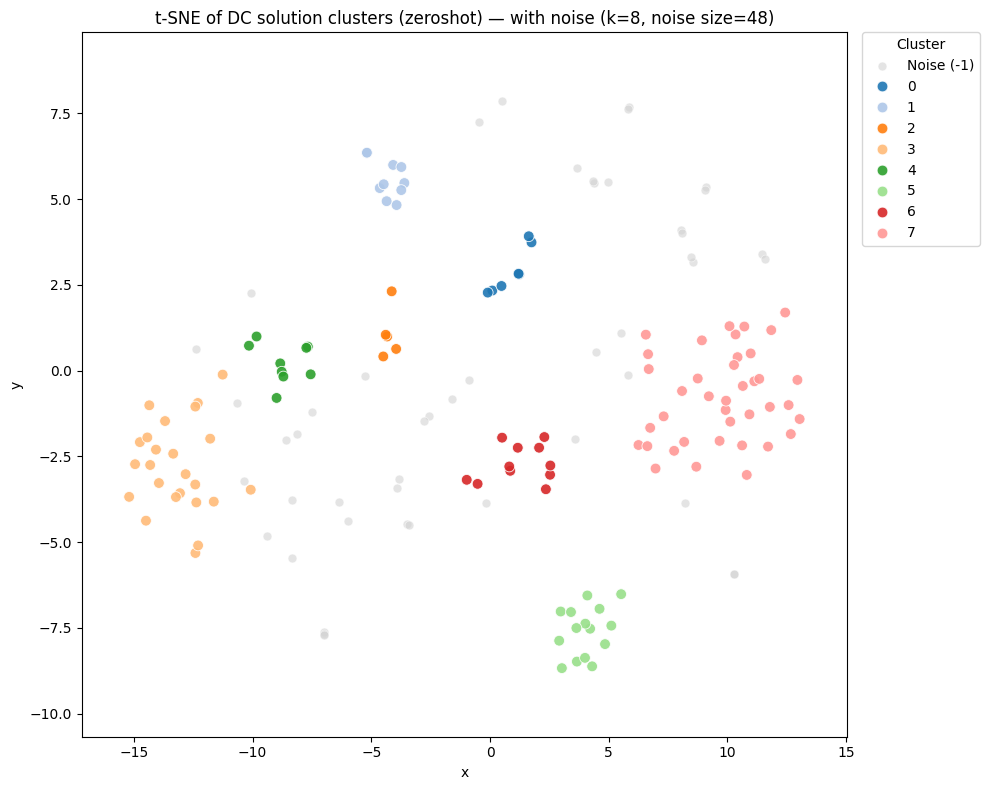

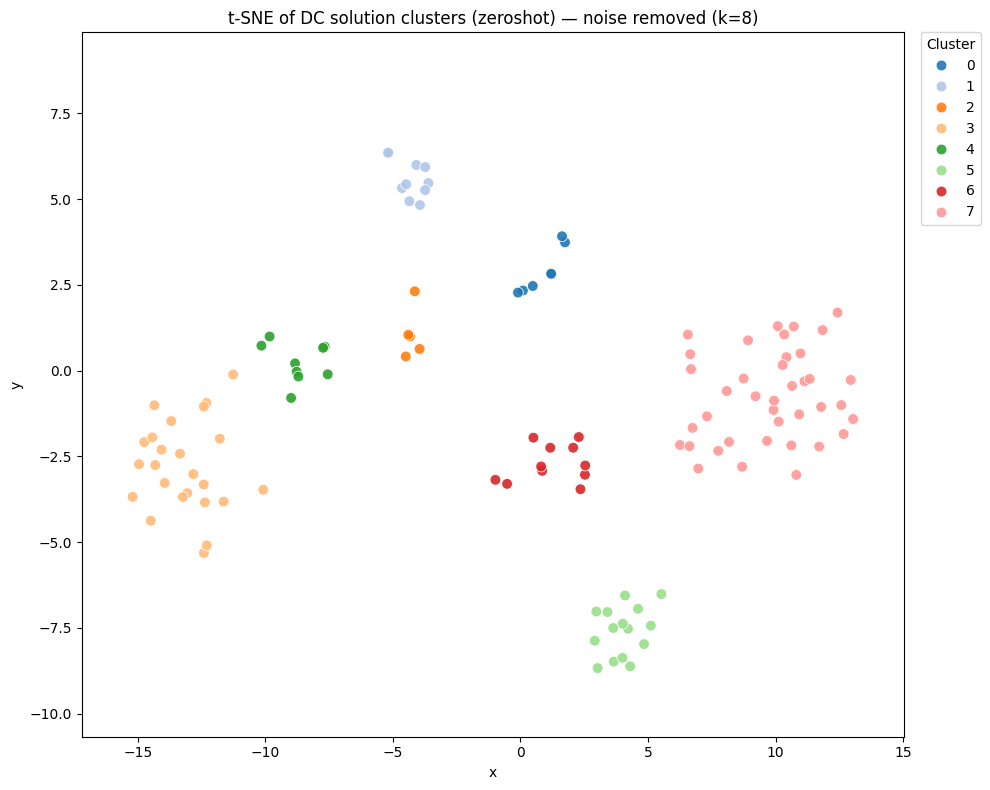

📝 Wrote summary: /Users/HP/Documents/EICS-2026/solProposeZeroshot/clustering_zeroshot/cluster_summary_zeroshot.txt
✅ Saved clustered data with names to: /Users/HP/Documents/EICS-2026/solProposeZeroshot/clustering_zeroshot/clustered_dc_solutions_with_names_zeroshot.csv


/var/folders/kr/646f6c153fv3167lv25vd8y40000gn/T/ipykernel_1089/2855551671.py:167: RuntimeWarning: divide by zero encountered in matmul
  sims = cl_emb @ centroid  # cosine (unit vectors)
/var/folders/kr/646f6c153fv3167lv25vd8y40000gn/T/ipykernel_1089/2855551671.py:167: RuntimeWarning: overflow encountered in matmul
  sims = cl_emb @ centroid  # cosine (unit vectors)
/var/folders/kr/646f6c153fv3167lv25vd8y40000gn/T/ipykernel_1089/2855551671.py:167: RuntimeWarning: invalid value encountered in matmul
  sims = cl_emb @ centroid  # cosine (unit vectors)


In [ ]:
# testing clustering for rows below 0.6 similarity
# === DC Solutions Clustering
    # - Embeddings (BGE large): BAAI/bge-large-en-v1.5
    # - HDBSCAN grid search to ~target clusters
    # - Final labels + t-SNE viz
    # - Cluster names (centroid medoid + TF-IDF fallback)
    # - Save CSV + summary

import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"  # silence HF fork warning

import numpy as np
import pandas as pd
from pathlib import Path
import hdbscan
from sentence_transformers import SentenceTransformer
from sklearn.manifold import TSNE
from sklearn.feature_extraction.text import TfidfVectorizer
import matplotlib.pyplot as plt
import seaborn as sns

# -------- paths & IO --------
out_dir = Path("clustering_zeroshot")
out_dir.mkdir(parents=True, exist_ok=True)
in_path = Path("semantic_analysis_zeroshot/8_biggerModel_bM_below_0_60_zeroshot.csv")
out_csv = out_dir / "clustered_dc_solutions_with_names_zeroshot.csv"
out_plot = out_dir / "tsne_dc_solution_clusters_zeroshot.png"
out_summary = out_dir / "cluster_summary_zeroshot.txt"

# -------- load data --------
df = pd.read_csv(in_path)

# combine title + explanation for embeddings from a csv
df["text_for_embedding"] = (
    df["solution_title"].fillna("") + ". " + df["explanation"].fillna("")
).str.strip()

# -------- embeddings --------
model = SentenceTransformer("BAAI/bge-large-en-v1.5")
embeddings = model.encode(
    df["text_for_embedding"].tolist(),
    batch_size=16,
    convert_to_tensor=True,
    normalize_embeddings=True
)
emb_np = embeddings.cpu().numpy()  # (n_samples, dim)
print(f"✅ Created embeddings for {len(df)} rows.")

# -------- HDBSCAN grid search (pick ~target clusters) --------
EPS_GRID = [0.01, 0.05, 0.10, 0.15]
SIZE_GRID = [5, 7]
TARGET_CLUSTERS = 10  # tweak as you like

def fit_hdb(emb, min_cluster_size, epsilon, min_samples=1, metric="euclidean"):
    cl = hdbscan.HDBSCAN(
        min_cluster_size=min_cluster_size,
        min_samples=min_samples,
        metric=metric,
        cluster_selection_epsilon=epsilon
    ).fit(emb)
    labels = cl.labels_
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = int(np.sum(labels == -1))
    return cl, n_clusters, n_noise

# grid search
for eps in EPS_GRID:
    for size in SIZE_GRID:
        cl, k, noise = fit_hdb(emb_np, size, eps, min_samples=1, metric="euclidean")


best = None
best_score = None
best_cfg = None

for eps in EPS_GRID:
    for size in SIZE_GRID:
        cl, k, noise = fit_hdb(emb_np, size, eps, min_samples=1, metric="euclidean")
        # prefer k close to target, then fewer noise points
        score = (abs(k - TARGET_CLUSTERS), noise)
        if (best is None) or (score < best_score):
            best, best_score = cl, score
            best_cfg = dict(min_cluster_size=size, epsilon=eps)

final_clusterer = best
labels = final_clusterer.labels_.astype(int)
df["cluster_id"] = labels

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = int(np.sum(labels == -1))
print(f"✅ Final: {n_clusters} clusters | noise={n_noise} | metric=euclidean | best={best_cfg}")

# -------- 2D visualization (t-SNE) --------
# Perplexity must be < n_samples and typically < (n-1)/3
perp = int(min(30, max(5, (len(df) - 1) // 3)))
tsne = TSNE(n_components=2, random_state=42, perplexity=perp)  # euclidean is fine on normalized vectors
coords = tsne.fit_transform(emb_np)
df["x"], df["y"] = coords[:, 0], coords[:, 1]

# handy counts & consistent axes
labels = df["cluster_id"].to_numpy()
k = len(set(labels)) - (1 if -1 in labels else 0)
noise_n = int((labels == -1).sum())
xlims = (df["x"].min() - 2, df["x"].max() + 2)
ylims = (df["y"].min() - 2, df["y"].max() + 2)

# choose a palette that scales beyond 20 clusters if needed
def cluster_palette(num_clusters: int):
    if num_clusters <= 20:
        return sns.color_palette("tab20", num_clusters)
    else:
        return sns.color_palette("husl", num_clusters)

# split data
df_noise = df[df["cluster_id"] == -1]
df_clust = df[df["cluster_id"] != -1].copy()

# -------- Plot A: WITH outliers (noise in gray) --------
plt.figure(figsize=(10, 8))
# plot noise first (underlay)
if len(df_noise):
    sns.scatterplot(
        data=df_noise, x="x", y="y",
        color="lightgray", s=40, alpha=0.6, label="Noise (-1)"
    )
# plot clusters on top
if len(df_clust):
    pal = cluster_palette(df_clust["cluster_id"].nunique())
    sns.scatterplot(
        data=df_clust, x="x", y="y",
        hue="cluster_id", palette=pal, s=60, alpha=0.9, legend="full"
    )

plt.title(f"t-SNE of DC solution clusters (zeroshot) — with noise (k={k}, noise size={noise_n})")
plt.xlim(xlims); plt.ylim(ylims)
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0.)
plt.tight_layout()
plt.savefig("clustering_zeroshot/tsne_clusters_with_noise_zeroshot.png", dpi=300)
plt.show()

# -------- Plot B: WITHOUT outliers (clean view) --------
plt.figure(figsize=(10, 8))
if len(df_clust):
    pal = cluster_palette(df_clust["cluster_id"].nunique())
    sns.scatterplot(
        data=df_clust, x="x", y="y",
        hue="cluster_id", palette=pal, s=60, alpha=0.9, legend="full"
    )

plt.title(f"t-SNE of DC solution clusters (zeroshot) — noise removed (k={k})")
plt.xlim(xlims); plt.ylim(ylims)
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0.)
plt.tight_layout()
plt.savefig("clustering_zeroshot/tsne_clusters_no_noise_zeroshot.png", dpi=300)
plt.show()

# -------- cluster names: centroid medoid + TF-IDF fallback --------
# centroid medoid title
cluster_names = {}
for cid, idxs in df.groupby("cluster_id").groups.items():
    if cid == -1:
        continue  # skip noise
    idxs = np.fromiter(idxs, dtype=int)
    cl_emb = emb_np[idxs]
    centroid = cl_emb.mean(axis=0)
    centroid /= (np.linalg.norm(centroid) + 1e-12)
    sims = cl_emb @ centroid  # cosine (unit vectors)
    rep_row_idx = idxs[int(np.argmax(sims))]
    cluster_names[cid] = str(df.loc[rep_row_idx, "solution_title"]).strip()

# TF-IDF phrase fallback (optional but nice)
texts_all = (df["solution_title"].fillna("") + ". " + df["explanation"].fillna("")).tolist()
tfidf = TfidfVectorizer(ngram_range=(2, 3), stop_words="english", max_features=4000)
X = tfidf.fit_transform(texts_all)
vocab = np.array(tfidf.get_feature_names_out())

def top_phrase_for_cluster(idxs):
    if len(idxs) == 0:
        return None
    scores = np.asarray(X[idxs].sum(axis=0)).ravel()
    if not np.any(scores):
        return None
    phrase = vocab[scores.argmax()].title()
    # small clean-ups
    phrase = phrase.replace(" Pv", " PV").replace(" Dc", " DC")
    return phrase

for cid, idxs in df.groupby("cluster_id").groups.items():
    if cid == -1:
        continue
    idxs = np.fromiter(idxs, dtype=int)
    phrase = top_phrase_for_cluster(idxs)
    # Use TF-IDF phrase if medoid title is too short/generic or phrase is clearly better
    medoid_title = cluster_names.get(cid, "")
    if phrase and (len(medoid_title) < 5 or phrase.lower() not in medoid_title.lower()):
        # Keep the medoid title somewhere if you like; here we replace the display name
        cluster_names[cid] = phrase

df["cluster_name"] = df["cluster_id"].map(cluster_names).fillna("Noise")

# -------- report & save --------
with open(out_summary, "w") as f:
    f.write(f"Best HDBSCAN params: {best_cfg}\n")
    f.write(f"Final clusters: {n_clusters}, noise points: {n_noise}\n\n")
    f.write("Cluster sizes:\n")
    f.write(df["cluster_id"].value_counts().sort_index().to_string())
print(f"📝 Wrote summary: {out_summary.resolve()}")

df.to_csv(out_csv, index=False)
print(f"✅ Saved clustered data with names to: {out_csv.resolve()}")


## Stage 6: Cluster review and proposal selection

This cell generates key phrases, summaries, and per-cluster text files to support author review. The noise group is retained in the supporting artifacts for completeness but excluded from proposal selection. Following review of the eight non-noise clusters, five DC proposals were selected for expert assessment.

In [ ]:
# Summarize clusters from a single CSV 
# Outputs:
#   - clustering_zeroshot/cluster_summaries_zeroshot.csv for all clusters
#   - clustering_zeroshot/cluster_text/cluster_{id}_{slug}.txt   (explanations concatenated per cluster)
# What it does:
#   1) Loads the clustered CSV (must contain columns: cluster_id, cluster_name, solution_title, explanation)
#   2) Builds discriminative keyphrases per cluster using class-based TF-IDF (c-TF-IDF)
#   3) Creates a concise summary row per cluster
#   4) Writes per-cluster .txt files with explanations for subsequent human review

import os
import re
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer

# --------- paths ---------
in_csv  = Path("clustering_zeroshot/clustered_dc_solutions_with_names_zeroshot.csv")  
out_dir = Path("clustering_zeroshot")
txt_dir = out_dir / "cluster_text"
out_dir.mkdir(parents=True, exist_ok=True)
txt_dir.mkdir(parents=True, exist_ok=True)

# --------- load ---------
df = pd.read_csv(in_csv)

# sanity checks
required_cols = {"cluster_id", "solution_title", "explanation"}
missing = required_cols - set(df.columns)
if missing:
    raise ValueError(f"CSV is missing required columns: {missing}")

# Option: keep noise/outliers for summaries
INCLUDE_NOISE = True

# Clean text helpers
def clean_text(s: str) -> str:
    s = str(s or "")
    s = s.replace("\n", " ").strip()
    s = re.sub(r"\s+", " ", s)
    return s

df["solution_title"] = df["solution_title"].astype(str).map(clean_text)
df["explanation"] = df["explanation"].astype(str).map(clean_text)
if "cluster_name" not in df.columns:
    df["cluster_name"] = df["cluster_id"].astype(str)

# --------- build one document per cluster (for class-based TF-IDF) ---------
# Concatenate all texts (title + explanation) per cluster into a single "cluster document"
cluster_docs = []
cluster_meta = []  # (cluster_id, cluster_name, n_items)
for cid, g in df.groupby("cluster_id", sort=True):
    if not INCLUDE_NOISE and int(cid) == -1:
        continue
    text = (g["solution_title"] + ". " + g["explanation"]).str.cat(sep=" ")
    cluster_docs.append(text)
    cluster_meta.append((int(cid), g["cluster_name"].iloc[0] if "cluster_name" in g.columns else str(cid), len(g)))

if not cluster_docs:
    raise ValueError("No clusters to summarize (maybe only noise and INCLUDE_NOISE=False?).")

# c-TF-IDF: fit TF-IDF across cluster-level
vectorizer = TfidfVectorizer(ngram_range=(1,3), stop_words="english", max_features=6000)
X = vectorizer.fit_transform(cluster_docs)
vocab = np.array(vectorizer.get_feature_names_out())

def top_terms_for_row(row_vec, k=8):
    """Return top-k terms (by TF-IDF) for a single cluster document (row of X)."""
    arr = np.asarray(row_vec.todense()).ravel()
    if not np.any(arr):
        return []
    idx = np.argsort(arr)[::-1][:k]
    terms = [vocab[i] for i in idx]
    # small clean-ups
    terms = [t.replace(" pv", " PV").replace(" dc", " DC") for t in terms]
    return terms

# --------- build summaries per cluster ---------
rows = []
for (cid, cname, n_items), row_vec in zip(cluster_meta, X):
    # terms
    keyphrases = top_terms_for_row(row_vec, k=8)
    keyphrases_str = ", ".join(keyphrases)

    # sample titles (up to 5) from the original df
    g = df[df["cluster_id"] == cid]
    sample_titles = g["solution_title"].dropna().astype(str).unique().tolist() # if slicing desired use [:5] (up to 5)
    sample_titles_str = " | ".join(sample_titles)

    # Concatenate explanations for the .txt file (full context)
    explanations_block = g["explanation"].dropna().astype(str).str.cat(sep="\n\n")
    # Save the text block
    slug = re.sub(r"[^a-z0-9]+", "-", str(cname).lower()).strip("-")[:50] or f"cluster-{cid}"
    txt_path = txt_dir / f"cluster_{cid:02d}_{slug or cid}.txt"
    with open(txt_path, "w", encoding="utf-8") as f:
        f.write(explanations_block)

    # Human-readable short summary (template; purely offline & deterministic)
    summary = (
        f"This cluster groups {n_items} DC solution proposal(s). "
        f"Common themes include: {keyphrases_str}. "
        f"Example solutions: {sample_titles_str}."
    )
    all_explanations = g['explanation'].dropna().astype(str).unique().tolist()
    all_explanations_str = "\n".join(f"{i+1}. {e}" for i, e in enumerate(all_explanations))

    rows.append({
        "cluster_id": cid,
        "cluster_name": cname,
        "n_items": n_items,
        "keyphrases": keyphrases_str,
        "sample_titles": sample_titles_str,
        "summary": summary,
        "explanations_text": all_explanations_str,
        # "cluster_text_file": str(txt_path)
    })

summ_df = pd.DataFrame(rows).sort_values(by="cluster_id").reset_index(drop=True)

# --------- save ---------
out_csv = out_dir / "cluster_summaries_zeroshot.csv"
summ_df.to_csv(out_csv, index=False)
print(f"✅ Wrote cluster summaries: {out_csv.resolve()}")
print(f"🗂️  Per-cluster text files saved in: {txt_dir.resolve()}")

# (optional) quick peek
display(summ_df.head(10))


✅ Wrote cluster summaries: /Users/HP/Documents/EICS-2026/solProposeZeroshot/clustering_zeroshot/cluster_summaries_zeroshot.csv
🗂️  Per-cluster text files saved in: /Users/HP/Documents/EICS-2026/solProposeZeroshot/clustering_zeroshot/cluster_text


,cluster_id,cluster_name,n_items,keyphrases,sample_titles,summary,explanations_text
0,-1,Noise,48,"energy, water, solar, management, storage, pow...",DC-Native Motor Drives | Energy-Efficient Buil...,This cluster groups 48 DC solution proposal(s)...,1. Motors designed to run directly on DC power...
1,0,Charging Stations,7,"charging, electric, charging stations, ev char...",EV Charging Stations for Industry | EV Chargin...,This cluster groups 7 DC solution proposal(s)....,1. Installing electric vehicle charging statio...
2,1,Building Integrated,10,"building, bipv, building integrated, building ...","""Building Integrated Photovoltaic Systems (BIP...",This cluster groups 10 DC solution proposal(s)...,1. The integration of solar panels directly in...
3,2,Integrated Renewable Energy Management System ...,5,"renewable, energy, renewable energy, integrate...",Building Integrated Renewable Energy Storage (...,This cluster groups 5 DC solution proposal(s)....,1. A system that integrates renewable energy s...
4,3,Led Lighting,24,"lighting, led, led lighting, efficient lightin...",Energy Efficient Lighting for Industry | Energ...,This cluster groups 24 DC solution proposal(s)...,1. Implementing LED lighting systems in indust...
5,4,Intelligent Building Management System,9,"management, energy, building, building managem...",Building Management System (BMS) | Energy Mana...,This cluster groups 9 DC solution proposal(s)....,1. A digital tool to monitor and manage energy...
6,5,Solar PV Tracking System,15,"tracking, solar, pv tracking, solar PV trackin...",Solar PV Tracking System | Solar Tracking Syst...,This cluster groups 15 DC solution proposal(s)...,1. A system that optimizes solar panel orienta...
7,6,Battery Storage,11,"hybrid, storage, battery, solar, energy, batte...",Energy Storage Hybrid System | Solar Hybrid Sy...,This cluster groups 11 DC solution proposal(s)...,1. A hybrid system that combines renewable ene...
8,7,Solar Power,39,"solar, ports, power, solar power, power ports,...",Solar PV for Ports | Solar Power for Ports | S...,This cluster groups 39 DC solution proposal(s)...,1. Harnessing solar power to generate electric...


### Author consolidation record

The authors reviewed the summaries, representative titles, key phrases, and complete explanations for the eight non-noise clusters. Related cluster themes were consolidated into five proposals:

- Cluster 0: electric vehicle charging stations
- Clusters 1, 2, and 4: Intelligent Building Energy Management System (IBEMS)
- Clusters 5 and 7: solar PV tracking and power systems
- Cluster 6: battery energy storage systems
- Cluster 3: LED lighting systems

The author-generated names, key phrases, objectives, and descriptions are recorded in `author-final.md`.

## Stage 7: Post-consolidation semantic fidelity validation

After the five proposals had been consolidated and written by the authors, `clusterAuthorSemFidelityCheck.py` compared their content with the corresponding evidence in `clustering_zeroshot/cluster_summaries_zeroshot.csv`. The BERTScore analysis used `roberta-large` to assess the key phrases and the combined objective and description. This validation assessed correspondence with the source clusters; it did not generate or select the proposals.

From the `solProposeZeroshot` directory, the validation can be reproduced with:

```bash
python clusterAuthorSemFidelityCheck.py
```

In [ ]:
from pathlib import Path
import pandas as pd

fidelity_path = Path("semantic-fidelity/cluster_author_semantic_fidelity.csv")
fidelity_df = pd.read_csv(fidelity_path)
display(fidelity_df)

In [5]:
# The latex table on mapping from clusters to the five proposals.
import csv
import re
from pathlib import Path


# Locate the source directory from common notebook locations.
candidates = [
    Path.cwd(),
    Path.cwd() / "solProposeZeroshot",
    Path.cwd() / "EICS-2026" / "solProposeZeroshot",
    Path.cwd().parent / "solProposeZeroshot",
]

BASE_DIR = next(
    (
        path for path in candidates
        if (path / "author-final.md").is_file()
        and (
            path / "clustering_zeroshot"
            / "cluster_summaries_zeroshot.csv"
        ).is_file()
    ),
    None,
)

if BASE_DIR is None:
    raise FileNotFoundError(
        "Run from Documents, EICS-2026, solProposeZeroshot, "
        "or expertsRatings."
    )


# Read the cluster summaries.
csv_file = (
    BASE_DIR / "clustering_zeroshot"
    / "cluster_summaries_zeroshot.csv"
)

with csv_file.open(newline="", encoding="utf-8-sig") as source:
    records = list(csv.DictReader(source))

clusters = {
    int(row["cluster_id"]): row
    for row in records
}

if len(clusters) != len(records):
    raise ValueError("Duplicate cluster identifiers were found.")


# Read proposal titles and cluster mappings from author-final.md.
author_text = (
    BASE_DIR / "author-final.md"
).read_text(encoding="utf-8")

blocks = re.split(
    r"(?m)^# solution:\s*",
    author_text,
)[1:]

proposals = []

for number, block in enumerate(blocks, start=1):
    mapping_match = re.match(
        r"(?:single_solution|combined_solution)"
        r"\s*\(cluster\s+([\d,\s]+)\)",
        block,
    )

    name_match = re.search(
        r"(?m)^## solution[_ ]name:\s*(.+)$",
        block,
    )

    if mapping_match is None or name_match is None:
        raise ValueError(
            f"Could not read the title or mapping for P{number}."
        )

    proposals.append({
        "proposal_id": f"P{number}",
        "title": name_match.group(1).strip(),
        "cluster_ids": [
            int(value.strip())
            for value in mapping_match.group(1).split(",")
        ],
    })


# Validate the five-proposal, eight-cluster mapping.
used_clusters = [
    cluster_id
    for proposal in proposals
    for cluster_id in proposal["cluster_ids"]
]

non_noise_clusters = set(clusters) - {-1}

if (
    len(proposals) != 5
    or len(used_clusters) != 8
    or len(set(used_clusters)) != 8
    or set(used_clusters) != non_noise_clusters
):
    raise ValueError(
        "Expected five proposals covering eight unique "
        "non-noise clusters."
    )

# Escape source text for LaTeX.
latex_characters = {
    "\\": r"\textbackslash{}",
    "&": r"\&",
    "%": r"\%",
    "$": r"\$",
    "#": r"\#",
    "_": r"\_",
    "{": r"\{",
    "}": r"\}",
    "~": r"\textasciitilde{}",
    "^": r"\textasciicircum{}",
    "|": r"\textbar{}",
}

def escape_latex(value):
    return re.sub(
        r"[\\&%$#_{}~^|]",
        lambda match: latex_characters[match.group(0)],
        str(value),
    )
def dedupe_cluster_summary(summary):
    """Remove repeated list entries without rewriting their wording."""

    def comparison_key(text):
        text = text.strip().strip("\"'“”‘’ .:;")
        text = re.sub(r"[\s\-–—]+", " ", text)
        return text.strip().casefold()

    def unique_entries(text, separator):
        seen = set()
        retained = []

        for entry in text.split(separator):
            entry = entry.strip()
            key = comparison_key(entry)

            if key and key not in seen:
                retained.append(entry)
                seen.add(key)

        return retained

    prefix, theme_marker, remainder = str(summary).partition(
        "Common themes include:"
    )

    themes, example_marker, examples = remainder.partition(
        "Example solutions:"
    )

    if not theme_marker or not example_marker:
        raise ValueError("Unexpected cluster-summary structure.")

    unique_themes = unique_entries(
        themes.strip().rstrip("."),
        ",",
    )

    unique_examples = unique_entries(
        examples.strip().rstrip("."),
        "|",
    )

    return (
        f"{prefix.strip()} "
        f"Common themes include: {', '.join(unique_themes)}. "
        f"Example solutions: {'; '.join(unique_examples)}."
    )

# Three columns. The final column receives most of the width.
# pdflscape rotates the page; longtable permits page breaks.
header = r"""
\begin{landscape}
\begingroup
\small
\setlength{\tabcolsep}{5pt}
\renewcommand{\arraystretch}{1.12}
\setlength{\LTleft}{0pt}
\setlength{\LTright}{0pt}

\begin{longtable}{@{}
>{\raggedright\arraybackslash}p{0.18\linewidth}
>{\raggedright\arraybackslash}p{0.20\linewidth}
>{\raggedright\arraybackslash}p{\dimexpr0.62\linewidth-4\tabcolsep\relax}
@{}}
\caption{Author consolidation of eight non-noise clusters into
five proposals for expert evaluation.}
\label{tab:cluster_proposal_compilation}\\
\toprule
Final proposal & Source cluster: ID and theme & Cluster summary \\
\midrule
\endfirsthead

\caption[]{Author consolidation of eight non-noise clusters into
five proposals for expert evaluation (continued).}\\
\toprule
Final proposal & Source cluster: ID and theme & Cluster summary \\
\midrule
\endhead

\midrule
\multicolumn{3}{r}{\footnotesize Continued on the next page}\\
\endfoot

\bottomrule
\multicolumn{3}{@{}p{\linewidth}@{}}{
\footnotesize
\textit{Key:} P1--P5 identify the final authored proposals.
Cluster IDs and themes follow the clustering output.
Rows grouped under a proposal identify its contributing clusters.
Summaries use the source CSV's \texttt{summary} field,
with repeated list entries removed within each cluster.
The first occurrence is retained, and example lists use semicolons.
The number of proposals stated in each summary refers to
generated proposals assigned to that cluster, not expert ratings.
The noise category (cluster $-1$) is excluded.
}\\
\endlastfoot
"""

body_rows = []

for proposal_index, proposal in enumerate(proposals):
    cluster_ids = proposal["cluster_ids"]

    for cluster_index, cluster_id in enumerate(cluster_ids):
        cluster = clusters[cluster_id]

        # Show the final proposal once within each group.
        if cluster_index == 0:
            proposal_cell = (
                rf"\textbf{{{proposal['proposal_id']}}}: "
                + escape_latex(proposal["title"])
            )
        else:
            proposal_cell = ""

        cluster_cell = (
            rf"\textbf{{{cluster_id}}}: "
            + escape_latex(cluster["cluster_name"])
        )

        # Preserve the summary wording; change only list separators.
        summary_cell = escape_latex(
        dedupe_cluster_summary(cluster["summary"])
        )

        # Keep contributing cluster rows together.
        row_end = (
            r"\\*"
            if cluster_index < len(cluster_ids) - 1
            else r"\\"
        )

        body_rows.append(
            f"{proposal_cell} & {cluster_cell} & "
            f"{summary_cell} {row_end}"
        )

    # Separate proposal groups.
    if proposal_index < len(proposals) - 1:
        body_rows.append(r"\midrule")


footer = r"""
\end{longtable}
\endgroup
\end{landscape}
"""

TABLE_DIR = BASE_DIR / "outputs" / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)

output_file = TABLE_DIR / "cluster_proposal_compilation.tex"

output_file.write_text(
    header + "\n".join(body_rows) + footer,
    encoding="utf-8",
)

print(f"LaTeX table exported to: {output_file}")

LaTeX table exported to: /Users/HP/Documents/EICS-2026/solProposeZeroshot/outputs/tables/cluster_proposal_compilation.tex
